In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ============================================================
# FINAL TASK 4 RESULTS
# ============================================================

results = {
    "ResNet34 Teacher": {
        "Type": "FP32 Teacher",
        "Best Epoch": 96,
        "Train Accuracy": 99.98,
        "Evaluation Accuracy": 94.91,
        "Loss": 0.6399,
        "Gap": 5.07,
        "Parameters": 21_282_122
    },

    "ResNet18 Baseline": {
        "Type": "FP32 Baseline",
        "Best Epoch": 98,
        "Train Accuracy": 100.00,
        "Evaluation Accuracy": 94.58,
        "Loss": 0.2609,
        "Gap": 5.42,
        "Parameters": 11_173_983
    },

    "Ternary ResNet18 Student": {
        "Type": "Ternary + KD + QAT",
        "Best Epoch": 139,
        "Train Accuracy": 91.03,
        "Evaluation Accuracy": 88.14,
        "Loss": None,
        "Gap": 2.89,
        "Parameters": 11_173_983
    }
}

df = pd.DataFrame(results).T

display(df)

,Type,Best Epoch,Train Accuracy,Evaluation Accuracy,Loss,Gap,Parameters
ResNet34 Teacher,FP32 Teacher,96,99.98,94.91,0.6399,5.07,21282122
ResNet18 Baseline,FP32 Baseline,98,100.0,94.58,0.2609,5.42,11173983
Ternary ResNet18 Student,Ternary + KD + QAT,139,91.03,88.14,None,2.89,11173983


In [2]:
results_dir = r"C:\Hamza_atdl\results"

os.makedirs(results_dir, exist_ok=True)

print("Results folder ready:")
print(results_dir)

Results folder ready:
C:\Hamza_atdl\results


In [3]:
comparison = df[
    [
        "Type",
        "Best Epoch",
        "Train Accuracy",
        "Evaluation Accuracy",
        "Loss",
        "Gap",
        "Parameters"
    ]
].copy()

display(comparison.round(2))

,Type,Best Epoch,Train Accuracy,Evaluation Accuracy,Loss,Gap,Parameters
ResNet34 Teacher,FP32 Teacher,96,99.98,94.91,0.6399,5.07,21282122
ResNet18 Baseline,FP32 Baseline,98,100.0,94.58,0.2609,5.42,11173983
Ternary ResNet18 Student,Ternary + KD + QAT,139,91.03,88.14,None,2.89,11173983


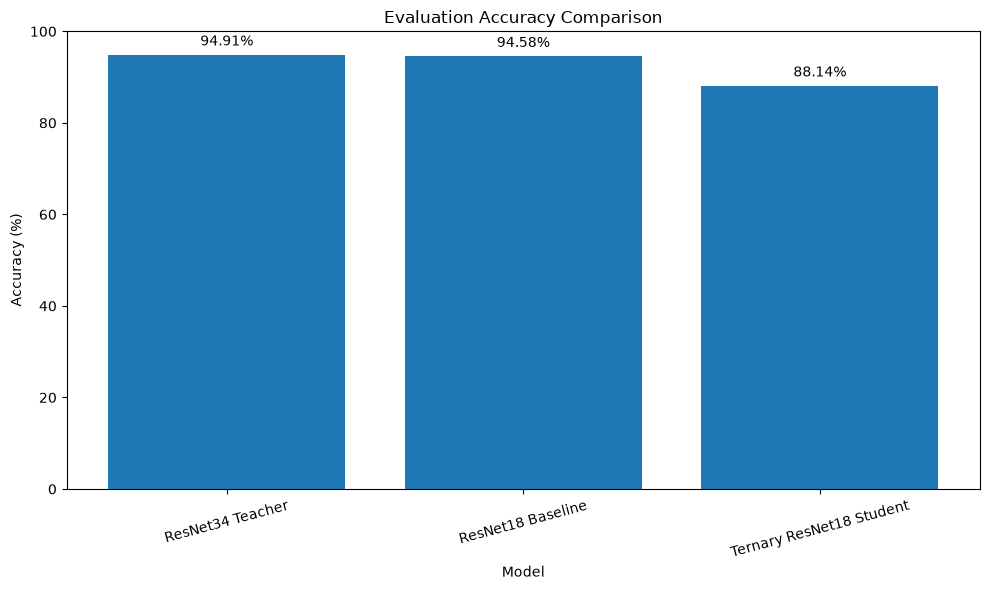

In [4]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    df.index,
    df["Evaluation Accuracy"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Evaluation Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15)

for bar, value in zip(bars, df["Evaluation Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "01_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

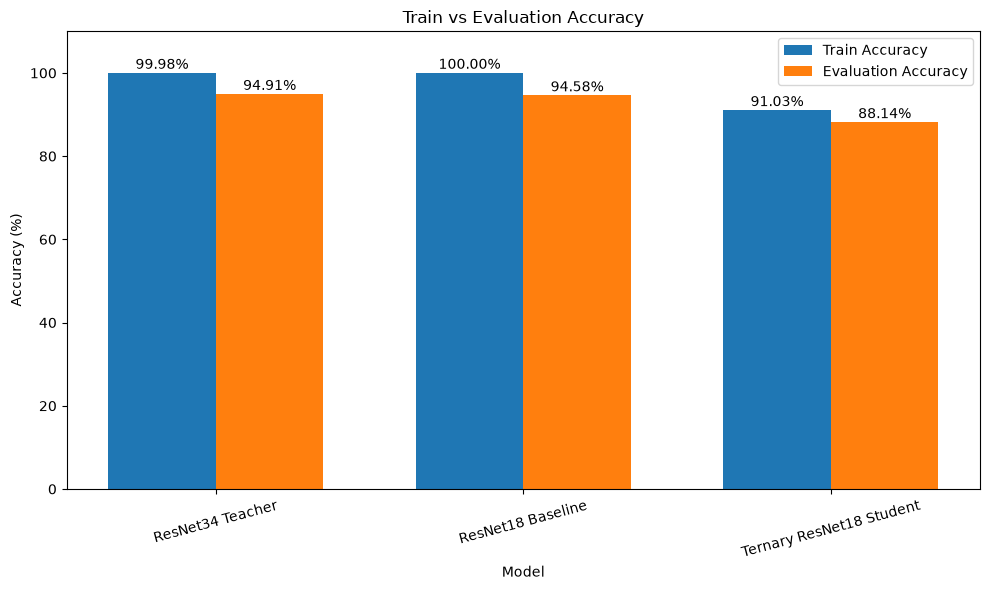

In [5]:
import numpy as np

x = np.arange(len(df))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width / 2,
    df["Train Accuracy"],
    width,
    label="Train Accuracy"
)

bars2 = plt.bar(
    x + width / 2,
    df["Evaluation Accuracy"],
    width,
    label="Evaluation Accuracy"
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Train vs Evaluation Accuracy")
plt.xticks(x, df.index, rotation=15)
plt.ylim(0, 110)
plt.legend()

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "02_train_vs_evaluation_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

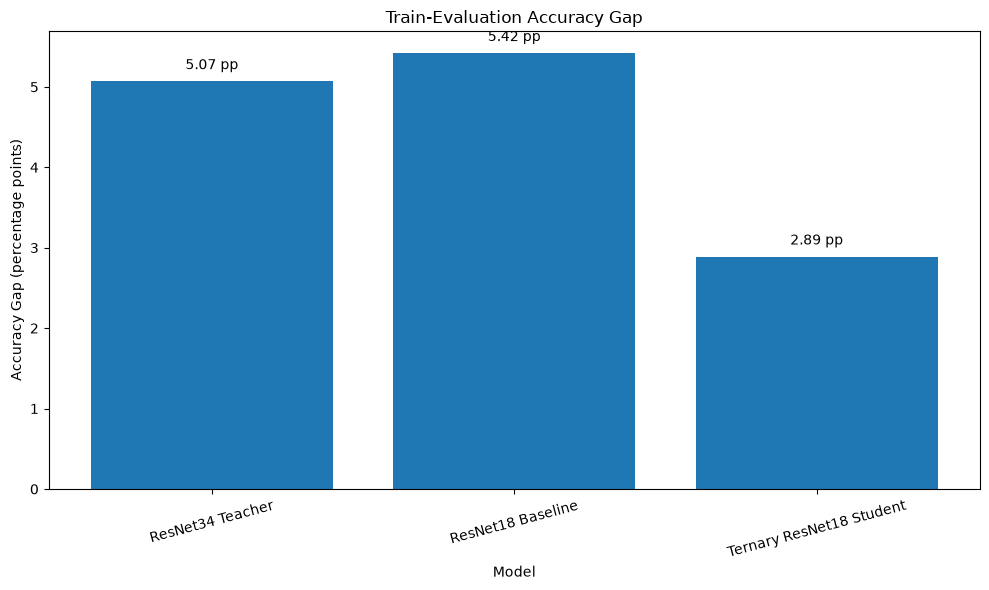

In [6]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    df.index,
    df["Gap"]
)

plt.ylabel("Accuracy Gap (percentage points)")
plt.xlabel("Model")
plt.title("Train-Evaluation Accuracy Gap")
plt.xticks(rotation=15)

for bar, value in zip(bars, df["Gap"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.15,
        f"{value:.2f} pp",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "03_generalization_gap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

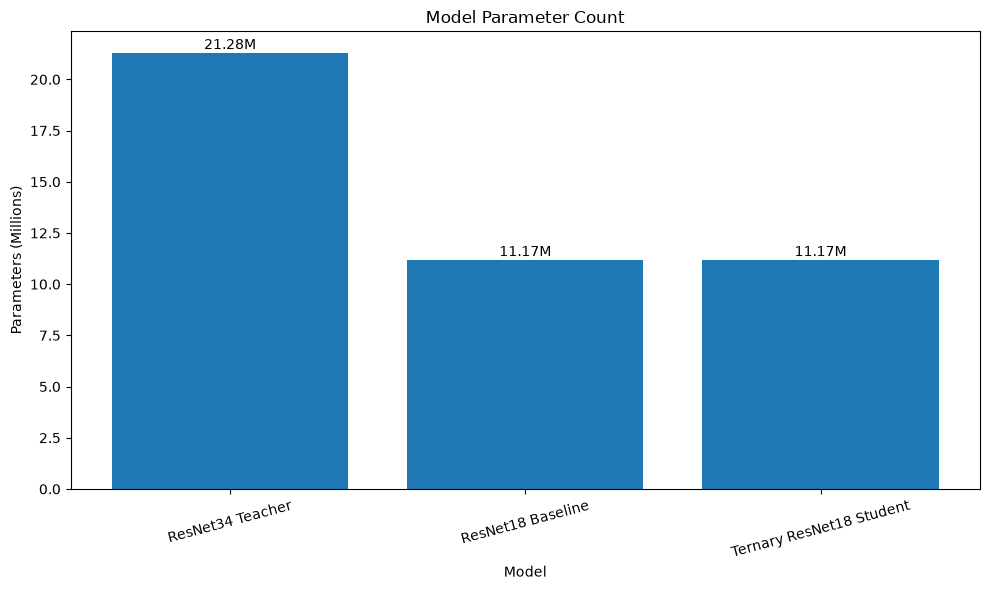

In [7]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    df.index,
    df["Parameters"] / 1e6
)

plt.ylabel("Parameters (Millions)")
plt.xlabel("Model")
plt.title("Model Parameter Count")
plt.xticks(rotation=15)

for bar, value in zip(bars, df["Parameters"] / 1e6):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f}M",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "04_parameter_count.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

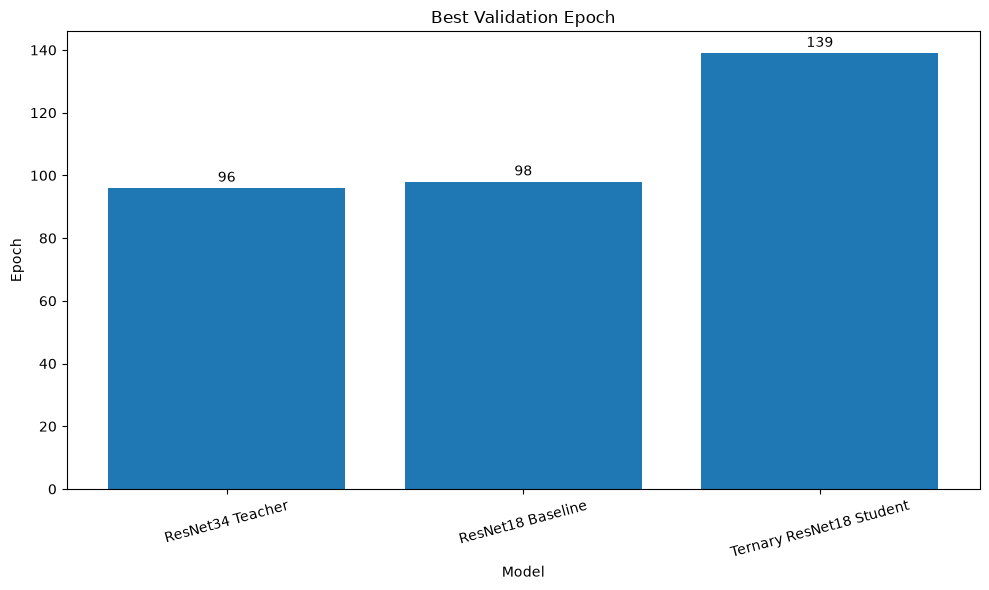

In [8]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    df.index,
    df["Best Epoch"]
)

plt.ylabel("Epoch")
plt.xlabel("Model")
plt.title("Best Validation Epoch")
plt.xticks(rotation=15)

for bar, value in zip(bars, df["Best Epoch"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        str(int(value)),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "05_best_epoch.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

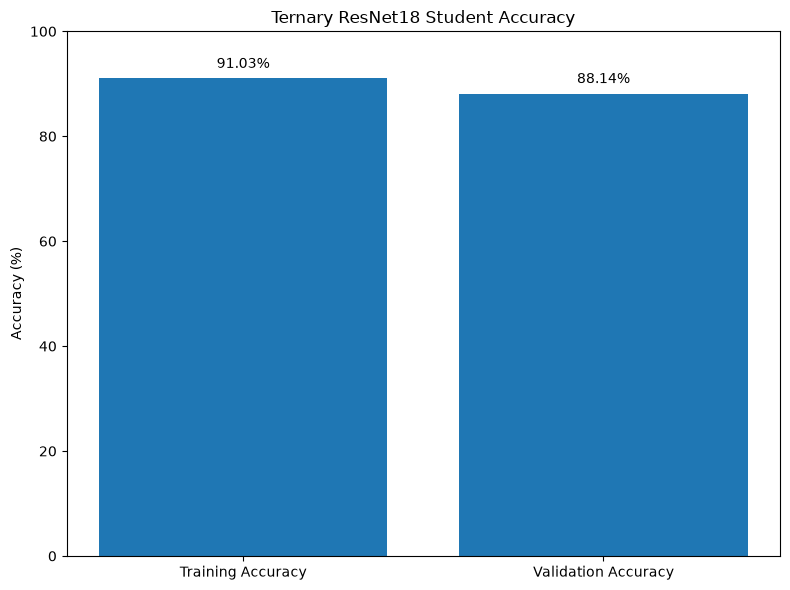

In [9]:
student_values = {
    "Training Accuracy": 91.03,
    "Validation Accuracy": 88.14
}

plt.figure(figsize=(8, 6))

bars = plt.bar(
    student_values.keys(),
    student_values.values()
)

plt.ylabel("Accuracy (%)")
plt.title("Ternary ResNet18 Student Accuracy")
plt.ylim(0, 100)

for bar, value in zip(bars, student_values.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "07_student_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
final_csv = os.path.join(
    results_dir,
    "FINAL_Task4_Three_Model_Comparison.csv"
)

df.to_csv(final_csv)

print("FINAL CSV saved:")
print(final_csv)

FINAL CSV saved:
C:\Hamza_atdl\results\FINAL_Task4_Three_Model_Comparison.csv


In [11]:
print("=" * 70)
print("FINAL TASK 4 — THREE MODEL COMPARISON")
print("=" * 70)

for model in df.index:
    print(f"\n{model}")
    print(f"  Type:               {df.loc[model, 'Type']}")
    print(f"  Best Epoch:         {df.loc[model, 'Best Epoch']}")
    print(f"  Train Accuracy:     {df.loc[model, 'Train Accuracy']:.2f}%")
    print(f"  Evaluation Accuracy:{df.loc[model, 'Evaluation Accuracy']:.2f}%")
    print(f"  Gap:                {df.loc[model, 'Gap']:.2f} pp")
    print(f"  Parameters:         {df.loc[model, 'Parameters']:,}")

print("\n" + "=" * 70)
print("All Task 4 plots and results saved.")
print("=" * 70)

FINAL TASK 4 — THREE MODEL COMPARISON

ResNet34 Teacher
  Type:               FP32 Teacher
  Best Epoch:         96
  Train Accuracy:     99.98%
  Evaluation Accuracy:94.91%
  Gap:                5.07 pp
  Parameters:         21,282,122

ResNet18 Baseline
  Type:               FP32 Baseline
  Best Epoch:         98
  Train Accuracy:     100.00%
  Evaluation Accuracy:94.58%
  Gap:                5.42 pp
  Parameters:         11,173,983

Ternary ResNet18 Student
  Type:               Ternary + KD + QAT
  Best Epoch:         139
  Train Accuracy:     91.03%
  Evaluation Accuracy:88.14%
  Gap:                2.89 pp
  Parameters:         11,173,983

All Task 4 plots and results saved.


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

RESULTS_DIR = r"C:\Hamza_atdl\results"
os.makedirs(RESULTS_DIR, exist_ok=True)

results = {
    "ResNet34 Teacher": {
        "Train Accuracy": 99.98,
        "Evaluation Accuracy": 94.91,
        "Gap": 5.07,
        "Parameters": 21_282_122,
        "Best Epoch": 96
    },

    "ResNet18 Baseline": {
        "Train Accuracy": 100.00,
        "Evaluation Accuracy": 94.58,
        "Gap": 5.42,
        "Parameters": 11_173_983,
        "Best Epoch": 98
    },

    "Ternary ResNet18 Student": {
        "Train Accuracy": 91.03,
        "Evaluation Accuracy": 88.14,
        "Gap": 2.89,
        "Parameters": 11_173_983,
        "Best Epoch": 139
    }
}

df = pd.DataFrame(results).T

display(df)

,Train Accuracy,Evaluation Accuracy,Gap,Parameters,Best Epoch
ResNet34 Teacher,99.98,94.91,5.07,21282122.0,96.0
ResNet18 Baseline,100.00,94.58,5.42,11173983.0,98.0
Ternary ResNet18 Student,91.03,88.14,2.89,11173983.0,139.0


In [16]:
import os
import torch
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = r"C:\Hamza_atdl"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

STUDENT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "ternary_resnet18_kd_best.pth"
)

# ============================================================
# LOAD STUDENT CHECKPOINT
# ============================================================

checkpoint = torch.load(
    STUDENT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully.")

# ============================================================
# FIND TERNARY WEIGHTS
# ============================================================

state_dict = checkpoint.get("model_state_dict", checkpoint)

ternary_layers = []
zero_count = 0
negative_count = 0
positive_count = 0
total_weights = 0

for name, tensor in state_dict.items():

    # Only convolution / linear weight tensors
    if not name.endswith(".weight"):
        continue

    # Ignore BatchNorm weights
    if tensor.ndim < 2:
        continue

    # Ignore if this is clearly not a convolution/linear weight
    if tensor.ndim not in [2, 4]:
        continue

    w = tensor.detach().float().cpu().numpy()

    total_weights += w.size

    zero_count += np.sum(w == 0)
    negative_count += np.sum(w < 0)
    positive_count += np.sum(w > 0)

    ternary_layers.append(name)

# ============================================================
# SPARSITY
# ============================================================

sparsity = (zero_count / total_weights) * 100

negative_percent = (negative_count / total_weights) * 100
zero_percent = (zero_count / total_weights) * 100
positive_percent = (positive_count / total_weights) * 100

print("\n========================================")
print("TERNARY WEIGHT ANALYSIS")
print("========================================")
print(f"Total weights analysed : {total_weights:,}")
print(f"Negative weights       : {negative_count:,}")
print(f"Zero weights           : {zero_count:,}")
print(f"Positive weights       : {positive_count:,}")
print(f"Sparsity               : {sparsity:.2f}%")
print(f"Negative               : {negative_percent:.2f}%")
print(f"Zero                   : {zero_percent:.2f}%")
print(f"Positive               : {positive_percent:.2f}%")

# ============================================================
# GRAPH 1 — TERNARY WEIGHT DISTRIBUTION
# ============================================================

labels = ["−α", "0", "+α"]
values = [
    negative_percent,
    zero_percent,
    positive_percent
]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.xlabel("Ternary Weight Value")
plt.ylabel("Percentage of Weights (%)")
plt.title("Ternary Weight Distribution")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, max(values) + 10)
plt.tight_layout()

path1 = os.path.join(
    RESULTS_DIR,
    "09_ternary_weight_distribution.png"
)

plt.savefig(path1, dpi=300)
plt.close()

print(f"\nSaved: {path1}")

# ============================================================
# GRAPH 2 — SPARSITY
# ============================================================

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Ternary Student"],
    [sparsity]
)

plt.ylabel("Zero Weights (%)")
plt.title("Ternary Student Weight Sparsity")

for bar, value in zip(bars, [sparsity]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, max(sparsity + 10, 10))
plt.tight_layout()

path2 = os.path.join(
    RESULTS_DIR,
    "10_student_sparsity.png"
)

plt.savefig(path2, dpi=300)
plt.close()

print(f"Saved: {path2}")

# ============================================================
# THEORETICAL COMPRESSION
# ============================================================

FP32_BITS = 32
TERNARY_BITS = 2

compression_ratio = FP32_BITS / TERNARY_BITS

student_params = 11_173_983

fp32_bits = student_params * FP32_BITS
ternary_bits = student_params * TERNARY_BITS

fp32_mb = fp32_bits / 8 / (1024 ** 2)
ternary_mb = ternary_bits / 8 / (1024 ** 2)

print("\n========================================")
print("THEORETICAL COMPRESSION")
print("========================================")
print(f"Parameters             : {student_params:,}")
print(f"FP32 storage           : {fp32_mb:.2f} MB")
print(f"Ternary weight storage : {ternary_mb:.2f} MB")
print(f"Theoretical ratio      : {compression_ratio:.1f}:1")

# ============================================================
# GRAPH 3 — THEORETICAL STORAGE
# ============================================================

plt.figure(figsize=(8, 5))

labels = ["FP32", "Ternary"]
storage = [fp32_mb, ternary_mb]

bars = plt.bar(labels, storage)

plt.ylabel("Theoretical Weight Storage (MB)")
plt.title("Theoretical Weight Storage Comparison")

for bar, value in zip(bars, storage):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.2f} MB",
        ha="center"
    )

plt.tight_layout()

path3 = os.path.join(
    RESULTS_DIR,
    "11_theoretical_storage.png"
)

plt.savefig(path3, dpi=300)
plt.close()

print(f"Saved: {path3}")

# ============================================================
# GRAPH 4 — COMPRESSION RATIO
# ============================================================

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["FP32 → Ternary"],
    [compression_ratio]
)

plt.ylabel("Theoretical Compression Ratio")
plt.title("Theoretical Ternary Compression Ratio")

for bar, value in zip(bars, [compression_ratio]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        f"{value:.1f}:1",
        ha="center"
    )

plt.ylim(0, compression_ratio + 5)
plt.tight_layout()

path4 = os.path.join(
    RESULTS_DIR,
    "12_theoretical_compression_ratio.png"
)

plt.savefig(path4, dpi=300)
plt.close()

print(f"Saved: {path4}")

# ============================================================
# SAVE NUMBERS TO TXT
# ============================================================

txt_path = os.path.join(
    RESULTS_DIR,
    "ternary_analysis.txt"
)

with open(txt_path, "w") as f:

    f.write("TERNARY RESNET18 STUDENT ANALYSIS\n")
    f.write("=================================\n\n")

    f.write(f"Total weights analysed: {total_weights:,}\n")
    f.write(f"Negative weights: {negative_count:,}\n")
    f.write(f"Zero weights: {zero_count:,}\n")
    f.write(f"Positive weights: {positive_count:,}\n\n")

    f.write(f"Negative percentage: {negative_percent:.2f}%\n")
    f.write(f"Zero percentage: {zero_percent:.2f}%\n")
    f.write(f"Positive percentage: {positive_percent:.2f}%\n")
    f.write(f"Sparsity: {sparsity:.2f}%\n\n")

    f.write(f"Parameters: {student_params:,}\n")
    f.write(f"FP32 theoretical storage: {fp32_mb:.2f} MB\n")
    f.write(f"Ternary theoretical storage: {ternary_mb:.2f} MB\n")
    f.write(f"Theoretical compression ratio: {compression_ratio:.1f}:1\n")

print(f"Saved: {txt_path}")

print("\n========================================")
print("DONE — ALL MISSING VALID GRAPHS CREATED")
print("========================================")

Checkpoint loaded successfully.

TERNARY WEIGHT ANALYSIS
Total weights analysed : 11,164,352
Negative weights       : 6,199,343
Zero weights           : 0
Positive weights       : 4,965,009
Sparsity               : 0.00%
Negative               : 55.53%
Zero                   : 0.00%
Positive               : 44.47%

Saved: C:\Hamza_atdl\results\09_ternary_weight_distribution.png
Saved: C:\Hamza_atdl\results\10_student_sparsity.png

THEORETICAL COMPRESSION
Parameters             : 11,173,983
FP32 storage           : 42.63 MB
Ternary weight storage : 2.66 MB
Theoretical ratio      : 16.0:1
Saved: C:\Hamza_atdl\results\11_theoretical_storage.png
Saved: C:\Hamza_atdl\results\12_theoretical_compression_ratio.png
Saved: C:\Hamza_atdl\results\ternary_analysis.txt

DONE — ALL MISSING VALID GRAPHS CREATED


<Figure size 640x480 with 0 Axes>